# Лабораторна робота №6. Експоненціальне згладжування Time Series
Дані: щомісячне виробництво електроенергії (як у Лр5). Виконано групу вимог 1.

## 1. Завантаження даних

In [1]:
import pandas as pd
df = pd.read_csv("../lab5/archive/Electric_Production.csv")

In [2]:
import sys
import os
sys.path.append(os.path.abspath('..')) 

from lab4.time_series_analysis.decomposition import *

In [3]:
df.columns = ['date', 'consumption']
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         397 non-null    str    
 1   consumption  397 non-null    float64
dtypes: float64(1), str(1)
memory usage: 6.3 KB


In [4]:
df['date'] = pd.to_datetime(df['date'])

## 2. Дослідження властивостей даних
Графік, STL-декомпозиція, статистика і тест Дікі-Фуллера.

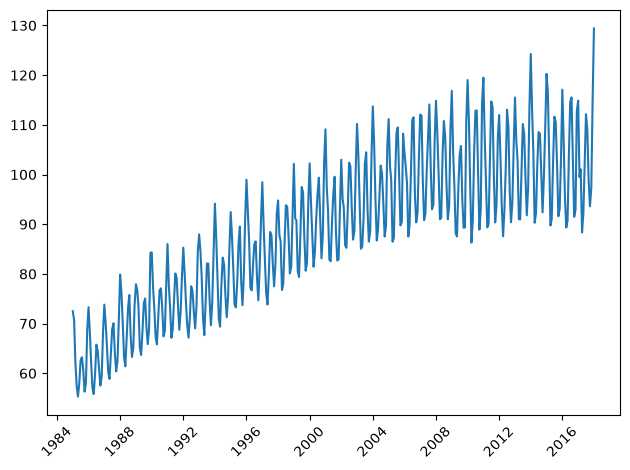

In [5]:
import matplotlib.pyplot as plt
plt.plot(df['date'], df['consumption'])
plt.xticks(rotation=45)
plt.tight_layout()

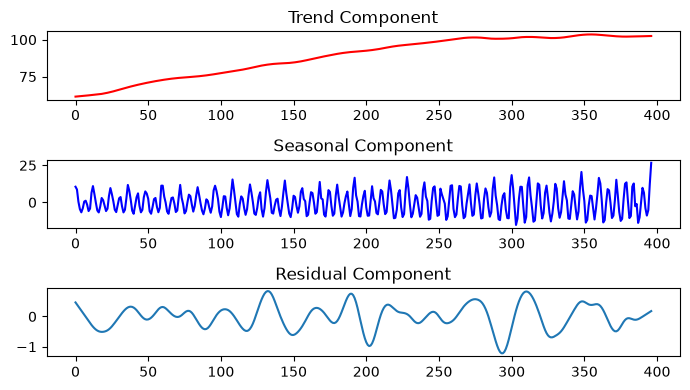

In [6]:
Y = df['consumption']
decomposed = decompose(Y, 12, 3, True)
plot_decomposition(decomposed)

Властивості
кількість елементів вбірки= 397
матиматичне сподівання ВВ= -0.43903892649852594
дисперсія ВВ = 61.65867176660544
СКВ ВВ= 7.8523035961815335 



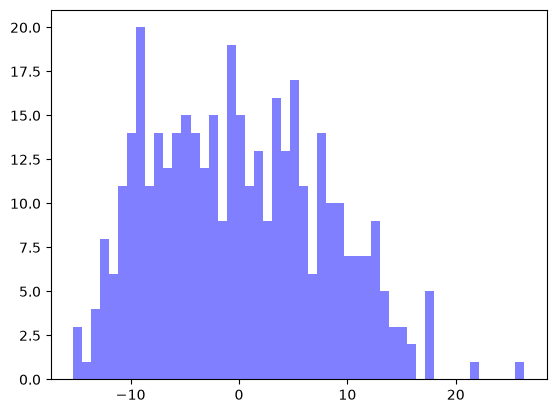

In [7]:
from lab4.time_series_analysis.stat_analysis import *
ts_stat_characteristics(Y, "Властивості")

Results of Dickey-Fuller Test_1:
ADF Statistic: -2.256990350047235
p-value: 0.1862146911658712
Critical Values:
   1%: -3.4476305904172904
   5%: -2.869155980820355
   10%: -2.570827146203181


/home/budulka/Documents/TimeSeriesLabs/lab4/time_series_analysis/stat_analysis.py:69: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series)


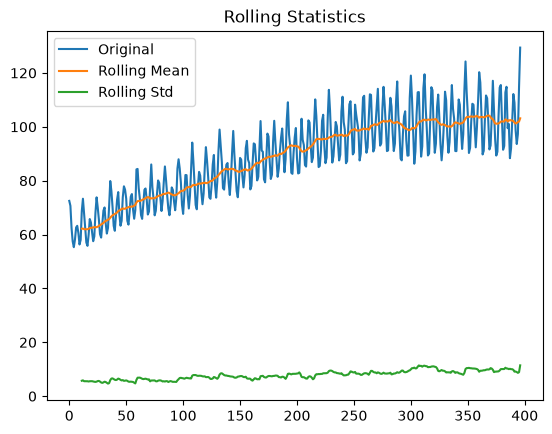

In [8]:
dfuller_test_1(Y)

# Ряд не є стаціонарним

ACF/PACF після сезонного диференціювання підтверджують річну сезонність (лаг 12).

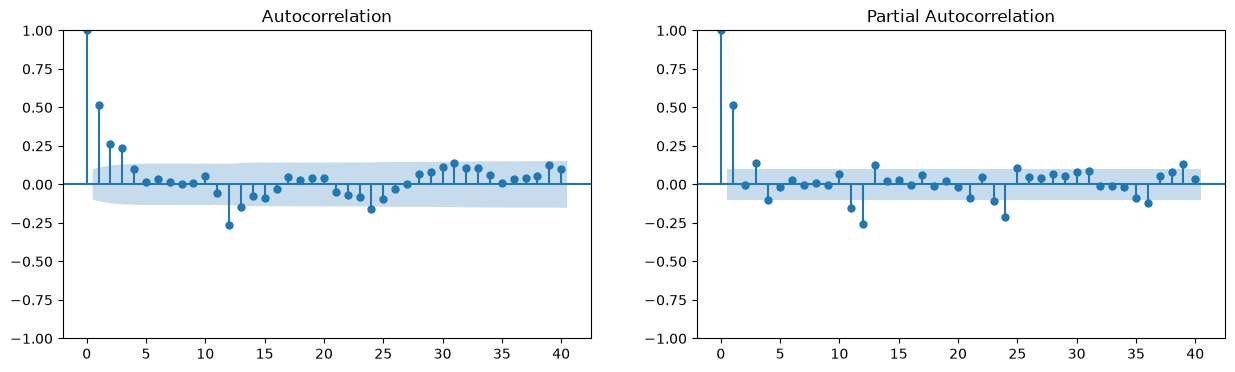

In [9]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

stationary_series = df['consumption'].diff(12).dropna()  
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
plot_acf(stationary_series, ax=axes[0], lags=40)
plot_pacf(stationary_series, ax=axes[1], lags=40)
plt.show()

## 3. Поділ на навчальну і тестову вибірки (85% / 15%)

In [10]:
test_rate = 0.15
train_size = int(len(Y) * (1 - test_rate))
test_size = len(Y) - train_size
train = Y[:train_size]
test = Y[train_size:]

In [11]:
len(train)

337

In [12]:
len(test)

60

# Наявні тренд і сезонність, використовуємо згладжування Холта-Вінтерса

In [13]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

model = ExponentialSmoothing(
    train,
    trend='add',        
    seasonal='add',
    damped_trend=True,
    seasonal_periods=12
).fit()

forecast = model.forecast(len(test))

## 4. Прогноз на тестовому інтервалі

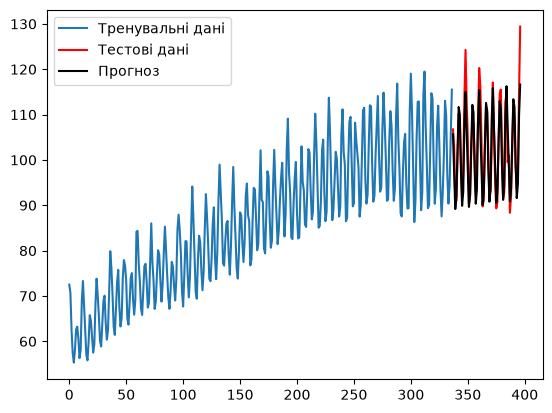

In [14]:
plt.plot(train.index, train, label='Тренувальні дані')
plt.plot(test.index, test, color='r', label='Тестові дані')
plt.plot(forecast, color='black', label='Прогноз')
plt.legend()

## 5. KPI моделі

In [15]:
from sklearn.metrics import r2_score, root_mean_squared_error, mean_squared_error, mean_absolute_error
mae = mean_absolute_error(test, forecast)
mse = mean_squared_error(test, forecast)
rmse = root_mean_squared_error(test, forecast)
r2 = r2_score(test, forecast)

In [16]:

print(f"MAE: {mae}, \nMSE: {mse},\nRMSE: {rmse} \nR2 score: {r2}")

MAE: 2.908780343089701, 
MSE: 15.383715035735714,
RMSE: 3.922207928671772 
R2 score: 0.838109720814356


In [17]:
model.params

{'smoothing_level': np.float64(0.4516549590062003),
 'smoothing_trend': np.float64(0.0),
 'smoothing_seasonal': np.float64(0.2573974041582718),
 'damping_trend': np.float64(0.995),
 'initial_level': np.float64(62.305112018014),
 'initial_trend': np.float64(0.22473698975142073),
 'initial_seasons': array([10.28418902,  6.44874305,  0.36518678, -5.35196046, -6.62593207,
        -2.38963249,  2.46292335,  2.29696122, -2.40611472, -6.16693985,
        -4.01026881,  5.50282828]),
 'use_boxcox': False,
 'lamda': None,
 'remove_bias': False}

Параметри моделі: α ≈ 0.45 (рівень), β = 0 (нахил тренду майже сталий), γ ≈ 0.26 (сезонність), φ = 0.995 (слабке згасання тренду).

## 6. Вибір оптимального типу експоненціального згладжування
Порівнюємо на тестовій вибірці SES, модель Холта (зі згасанням тренду і без нього) та Холта-Вінтерса (адитивна і мультиплікативна сезонність). Критерії: RMSE, MAE, R² і AIC.

In [18]:
candidates = {
    'SES':                    dict(trend=None, seasonal=None),
    'Holt':                   dict(trend='add', seasonal=None),
    'Holt (damped)':          dict(trend='add', seasonal=None, damped_trend=True),
    'Holt-Winters add':       dict(trend='add', seasonal='add', seasonal_periods=12),
    'Holt-Winters add damped':dict(trend='add', seasonal='add', seasonal_periods=12, damped_trend=True),
    'Holt-Winters mul damped':dict(trend='add', seasonal='mul', seasonal_periods=12, damped_trend=True),
}

rows, forecasts = [], {}
for name, cfg in candidates.items():
    fitted = ExponentialSmoothing(train, **cfg).fit()
    fc = fitted.forecast(len(test))
    forecasts[name] = fc
    rows.append({'Модель': name,
                 'MAE': mean_absolute_error(test, fc),
                 'RMSE': root_mean_squared_error(test, fc),
                 'R2': r2_score(test, fc),
                 'AIC': fitted.aic})

comparison = pd.DataFrame(rows).set_index('Модель').sort_values('RMSE')
comparison.round(3)

,MAE,RMSE,R2,AIC
Модель,,,,
Holt-Winters mul damped,2.863,3.821,0.846,583.348
Holt-Winters add damped,2.909,3.922,0.838,600.272
Holt-Winters add,3.563,4.319,0.804,598.637
SES,13.500,15.854,-1.645,1350.244
Holt (damped),14.130,16.453,-1.849,1356.204
Holt,16.910,19.149,-2.859,1354.142


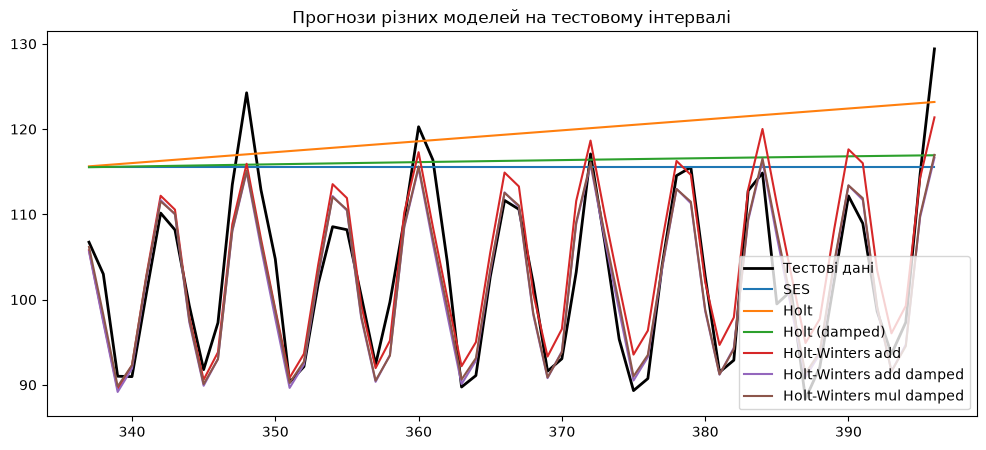

In [19]:
plt.figure(figsize=(12, 5))
plt.plot(test.index, test, color='black', linewidth=2, label='Тестові дані')
for name, fc in forecasts.items():
    plt.plot(test.index, fc, label=name)
plt.title('Прогнози різних моделей на тестовому інтервалі')
plt.legend()
plt.show()

## 7. Екстраполяція за межі спостережень
Найкращу за RMSE модель перенавчаємо на всьому ряді й прогнозуємо на 0.5 інтервалу спостереження.

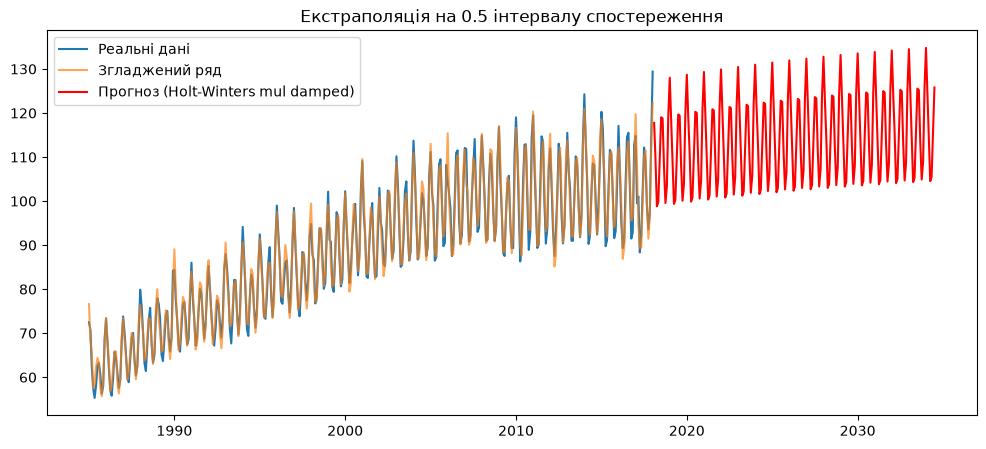

Обрана модель: Holt-Winters mul damped
RMSE на всьому ряді (in-sample): 2.4158368473015


In [20]:
best_name = comparison.index[0]
best_model = ExponentialSmoothing(Y, **candidates[best_name]).fit()

n_forecast = int(0.5 * len(Y))
future_dates = pd.date_range(start=df['date'].iloc[-1] + pd.DateOffset(months=1),
                             periods=n_forecast, freq='MS')
future = best_model.forecast(n_forecast)

plt.figure(figsize=(12, 5))
plt.plot(df['date'], Y, label='Реальні дані')
plt.plot(df['date'], best_model.fittedvalues, alpha=0.7, label='Згладжений ряд')
plt.plot(future_dates, future.values, color='red', label=f'Прогноз ({best_name})')
plt.title('Екстраполяція на 0.5 інтервалу спостереження')
plt.legend()
plt.show()

print('Обрана модель:', best_name)
print('RMSE на всьому ряді (in-sample):', root_mean_squared_error(Y, best_model.fittedvalues))

## Висновки
Ряд нестаціонарний (p-value = 0.19) і має тренд та річну сезонність, тому моделі без сезонної складової (SES і Холт) виявилися непридатними: R² < 0, RMSE 16–19. Найкращою за всіма критеріями стала модель Холта-Вінтерса з мультиплікативною сезонністю та згасаючим трендом (MAE 2.86, RMSE 3.82, R² 0.85, мінімальний AIC). Мультиплікативна сезонність краща, бо амплітуда сезонних коливань зростає разом з рівнем ряду. Згасання тренду теж покращує прогноз: без нього RMSE адитивної моделі зростає з 3.92 до 4.32. Прогноз на 0.5 інтервалу продовжує сезонний патерн з помірним зростанням і за точністю близький до SARIMA з Лр5 (RMSE ≈ 4.0), хоча тестові інтервали там трохи інші.